# Stroke Prediction Using Machine Learning

## 1. Business Understanding

### Problem Statement
Stroke is a serious medical condition. This project uses patient demographic, health, and lifestyle information to build a machine learning classification model that predicts whether a record belongs to the stroke class.

### Objective
To analyze patient data, train classification models, compare their performance, and deploy the selected model using Gradio.

### Machine Learning Type
Supervised Learning — Binary Classification.

### Target Variable
`stroke`

- `0` — No recorded stroke
- `1` — Recorded stroke

### Dataset
Stroke Prediction Dataset from Kaggle.

### Tools
Python, Jupyter Notebook, Pandas, Matplotlib, Seaborn, Scikit-learn, Joblib, and Gradio.

### Expected Outcome
A trained machine learning pipeline and an interactive application for educational demonstration.

**Disclaimer:** This project is not a medical diagnostic tool and must not be used to make healthcare decisions.

### Step 2: Install the required libraries

In [45]:
%pip install pandas numpy matplotlib seaborn scikit-learn joblib gradio

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: C:\Users\VENU\AppData\Local\Python\pythoncore-3.14-64\python.exe -m pip install --upgrade pip


### Step 3: Load the dataset

In [46]:
# Import Pandas for handling tabular data
import pandas as pd

# Load the dataset
df = pd.read_csv("healthcare-dataset-stroke-data.csv")

# Display the first five rows
df.head()

,id,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,9046,Male,67.0,0,1,Yes,Private,Urban,228.69,36.6,formerly smoked,1
1,51676,Female,61.0,0,0,Yes,Self-employed,Rural,202.21,NaN,never smoked,1
2,31112,Male,80.0,0,1,Yes,Private,Rural,105.92,32.5,never smoked,1
3,60182,Female,49.0,0,0,Yes,Private,Urban,171.23,34.4,smokes,1
4,1665,Female,79.0,1,0,Yes,Self-employed,Rural,174.12,24.0,never smoked,1


### Step 4: Understand the dataset

#### 4.1 Check the number of rows and columns

In [47]:
# Check dataset dimensions
df.shape

(5110, 12)

#### 4.2 Display column names

In [48]:
# Display all column names
df.columns.tolist()

['id',
 'gender',
 'age',
 'hypertension',
 'heart_disease',
 'ever_married',
 'work_type',
 'Residence_type',
 'avg_glucose_level',
 'bmi',
 'smoking_status',
 'stroke']

#### 4.3 Check data types and missing values

In [49]:
# Check column data types and non-null values
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5110 entries, 0 to 5109
Data columns (total 12 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   id                 5110 non-null   int64  
 1   gender             5110 non-null   str    
 2   age                5110 non-null   float64
 3   hypertension       5110 non-null   int64  
 4   heart_disease      5110 non-null   int64  
 5   ever_married       5110 non-null   str    
 6   work_type          5110 non-null   str    
 7   Residence_type     5110 non-null   str    
 8   avg_glucose_level  5110 non-null   float64
 9   bmi                4909 non-null   float64
 10  smoking_status     5110 non-null   str    
 11  stroke             5110 non-null   int64  
dtypes: float64(3), int64(4), str(5)
memory usage: 479.2 KB


In [50]:
# Count missing values in each column
df.isnull().sum()

id                     0
gender                 0
age                    0
hypertension           0
heart_disease          0
ever_married           0
work_type              0
Residence_type         0
avg_glucose_level      0
bmi                  201
smoking_status         0
stroke                 0
dtype: int64

#### 4.4 Generate statistical information

In [51]:
# Summary of numerical columns
df.describe()

,id,age,hypertension,heart_disease,avg_glucose_level,bmi,stroke
count,5110.000000,5110.000000,5110.000000,5110.000000,5110.000000,4909.000000,5110.000000
mean,36517.829354,43.226614,0.097456,0.054012,106.147677,28.893237,0.048728
std,21161.721625,22.612647,0.296607,0.226063,45.283560,7.854067,0.215320
min,67.000000,0.080000,0.000000,0.000000,55.120000,10.300000,0.000000
25%,17741.250000,25.000000,0.000000,0.000000,77.245000,23.500000,0.000000
50%,36932.000000,45.000000,0.000000,0.000000,91.885000,28.100000,0.000000
75%,54682.000000,61.000000,0.000000,0.000000,114.090000,33.100000,0.000000
max,72940.000000,82.000000,1.000000,1.000000,271.740000,97.600000,1.000000


#### 4.5 Check duplicate records

In [52]:
# Count duplicate rows
df.duplicated().sum()

np.int64(0)

### Step 5: Clean the dataset

In [53]:
# Remove duplicate records
df = df.drop_duplicates().copy()

# Remove the ID column if it exists
if "id" in df.columns:
    df = df.drop(columns=["id"])

# Display the cleaned dataset
df.head()

,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,Male,67.0,0,1,Yes,Private,Urban,228.69,36.6,formerly smoked,1
1,Female,61.0,0,0,Yes,Self-employed,Rural,202.21,NaN,never smoked,1
2,Male,80.0,0,1,Yes,Private,Rural,105.92,32.5,never smoked,1
3,Female,49.0,0,0,Yes,Private,Urban,171.23,34.4,smokes,1
4,Female,79.0,1,0,Yes,Self-employed,Rural,174.12,24.0,never smoked,1


In [54]:
# Verify the cleaned dataset
print("Dataset shape:", df.shape)
print("Total missing values:", df.isnull().sum().sum())
print("Duplicate rows:", df.duplicated().sum())

Dataset shape: (5110, 11)
Total missing values: 201
Duplicate rows: 0


**Important**: Do not fill missing values yet. We will handle them after splitting the data to avoid data leakage.

### Step 6: Exploratory Data Analysis (EDA)

#### 6.1 Analyze stroke distribution

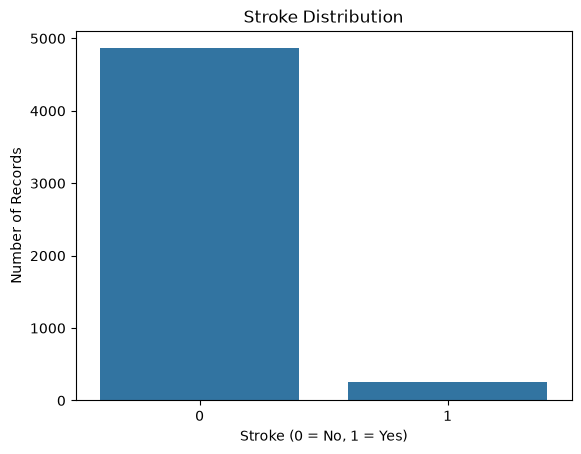

stroke
0    4861
1     249
Name: count, dtype: int64


In [55]:
# Import visualization libraries when first needed
import matplotlib.pyplot as plt
import seaborn as sns

# Plot stroke distribution
sns.countplot(data=df, x="stroke")

plt.title("Stroke Distribution")
plt.xlabel("Stroke (0 = No, 1 = Yes)")
plt.ylabel("Number of Records")
plt.show()

# Display class counts
print(df["stroke"].value_counts())

**Observation**: In the standard dataset, the stroke-positive class is much smaller than the non-stroke class. This class imbalance must be considered during model evaluation.

#### 6.2 Analyze age distribution

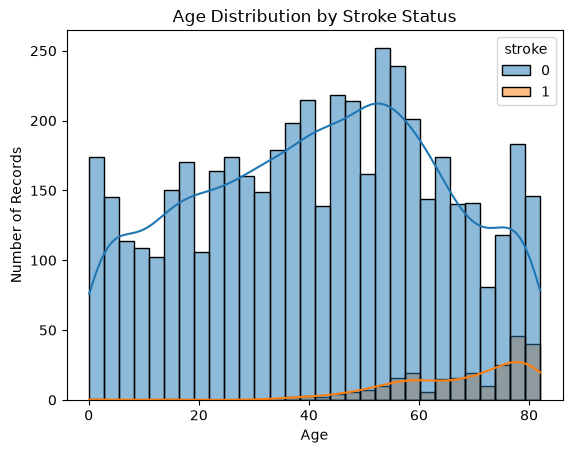

In [56]:
# Plot age distribution by stroke status
sns.histplot(
    data=df,
    x="age",
    hue="stroke",
    bins=30,
    kde=True
)

plt.title("Age Distribution by Stroke Status")
plt.xlabel("Age")
plt.ylabel("Number of Records")
plt.show()

#### 6.3 Analyze average glucose level

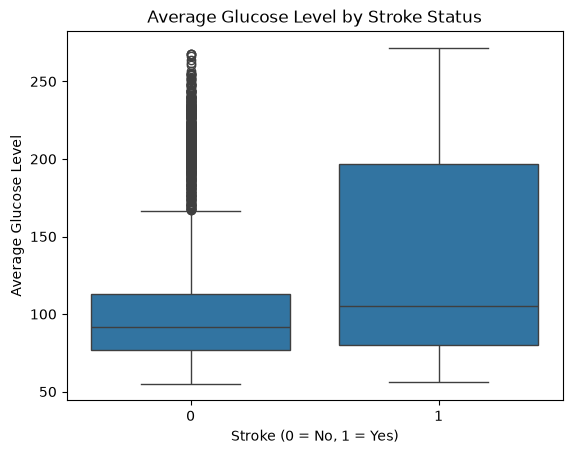

In [57]:
# Compare glucose levels by stroke status
sns.boxplot(data=df, x="stroke", y="avg_glucose_level")

plt.title("Average Glucose Level by Stroke Status")
plt.xlabel("Stroke (0 = No, 1 = Yes)")
plt.ylabel("Average Glucose Level")
plt.show()

#### 6.4 Analyze BMI

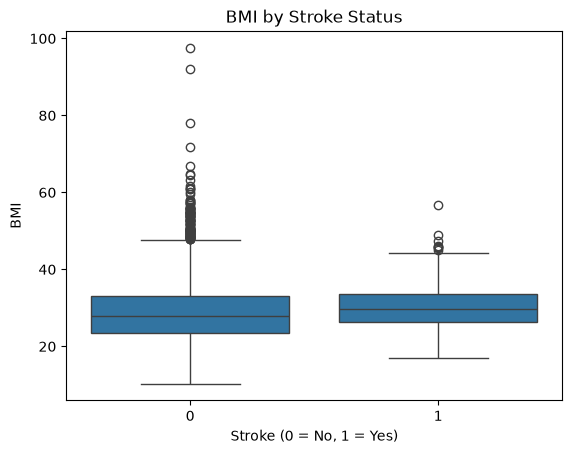

In [58]:
# Compare BMI by stroke status
sns.boxplot(data=df, x="stroke", y="bmi")

plt.title("BMI by Stroke Status")
plt.xlabel("Stroke (0 = No, 1 = Yes)")
plt.ylabel("BMI")
plt.show()

#### 6.5 Analyze hypertension

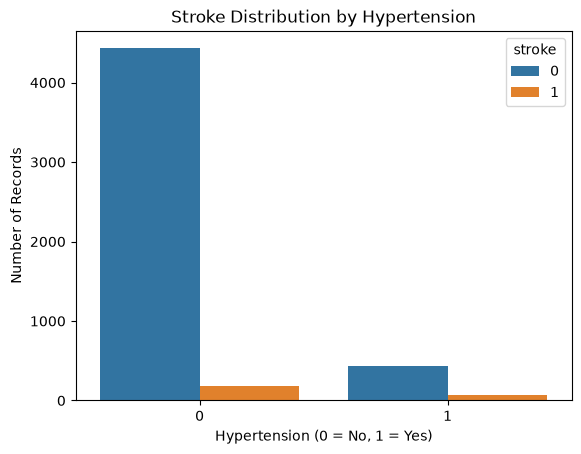

In [59]:
# Compare stroke counts for hypertension groups
sns.countplot(data=df, x="hypertension", hue="stroke")

plt.title("Stroke Distribution by Hypertension")
plt.xlabel("Hypertension (0 = No, 1 = Yes)")
plt.ylabel("Number of Records")
plt.show()

#### 6.6 Analyze heart disease

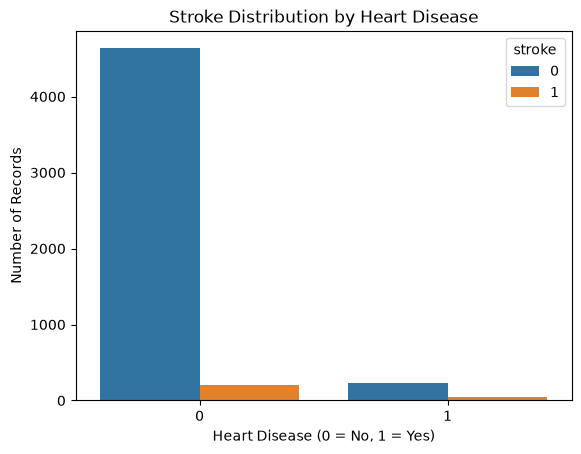

In [60]:
# Compare stroke counts for heart disease groups
sns.countplot(data=df, x="heart_disease", hue="stroke")

plt.title("Stroke Distribution by Heart Disease")
plt.xlabel("Heart Disease (0 = No, 1 = Yes)")
plt.ylabel("Number of Records")
plt.show()

#### 6.7 Analyze numerical feature correlations

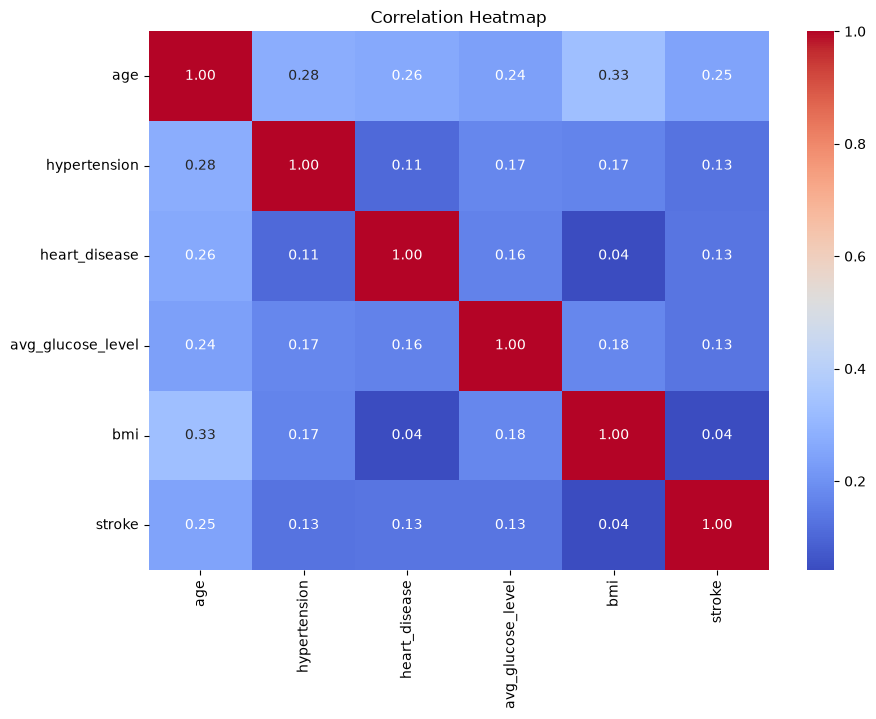

In [61]:
# Select numerical columns
numeric_df = df.select_dtypes(include="number")

# Plot correlation heatmap
plt.figure(figsize=(10, 7))

sns.heatmap(
    numeric_df.corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap")
plt.show()

### Step 7: Separate features and target

In [62]:
# Separate input features and target variable
X = df.drop(columns=["stroke"])
y = df["stroke"].astype(int)

print("Input feature shape:", X.shape)
print("Target shape:", y.shape)

print("\nInput columns:")
print(X.columns.tolist())

print("\nTarget distribution:")
print(y.value_counts())

Input feature shape: (5110, 10)
Target shape: (5110,)

Input columns:
['gender', 'age', 'hypertension', 'heart_disease', 'ever_married', 'work_type', 'Residence_type', 'avg_glucose_level', 'bmi', 'smoking_status']

Target distribution:
stroke
0    4861
1     249
Name: count, dtype: int64


### Step 8: Split training and testing data

In [63]:
# Import train_test_split when needed
from sklearn.model_selection import train_test_split

# Split the dataset
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts())

print("\nTesting target distribution:")
print(y_test.value_counts())

Training data: (4088, 10)
Testing data: (1022, 10)

Training target distribution:
stroke
0    3889
1     199
Name: count, dtype: int64

Testing target distribution:
stroke
0    972
1     50
Name: count, dtype: int64


### Step 9: Preprocess numerical and categorical features

#### 9.1 Identify numerical and categorical columns

In [64]:
# Identify numerical columns
numeric_features = X_train.select_dtypes(
    include="number"
).columns.tolist()

# Identify categorical columns
categorical_features = X_train.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

print("Numerical features:", numeric_features)
print("Categorical features:", categorical_features)

Numerical features: ['age', 'hypertension', 'heart_disease', 'avg_glucose_level', 'bmi']
Categorical features: ['gender', 'ever_married', 'work_type', 'Residence_type', 'smoking_status']


C:\Users\VENU\AppData\Local\Temp\ipykernel_2060\1184605108.py:7: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_features = X_train.select_dtypes(


#### 9.2 Create the numerical preprocessing pipeline

In [65]:
# Import preprocessing tools
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

# Handle missing numerical values and scale features
numeric_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]
)

print("Numerical preprocessing pipeline created.")

Numerical preprocessing pipeline created.


#### 9.3 Create the categorical preprocessing pipeline

In [66]:
# Import OneHotEncoder
from sklearn.preprocessing import OneHotEncoder

# Handle missing categorical values and encode categories
categorical_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        (
            "encoder",
            OneHotEncoder(
                handle_unknown="ignore",
                drop="first"
            )
        )
    ]
)

print("Categorical preprocessing pipeline created.")

Categorical preprocessing pipeline created.


#### 9.4 Combine both preprocessing pipelines

In [67]:
# Import ColumnTransformer
from sklearn.compose import ColumnTransformer

# Apply different preprocessing to different columns
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

print("Complete preprocessing pipeline created.")

Complete preprocessing pipeline created.


### Step 10: Build machine learning models

#### 10.1 Import the required algorithms

In [68]:
# Import the classification algorithms
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

# Import metrics for evaluation
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    ConfusionMatrixDisplay
)

print("Models and evaluation metrics imported.")

Models and evaluation metrics imported.


#### 10.2 Create the models

In [69]:
# Define the classification models
models = {
    "Logistic Regression": LogisticRegression(
        max_iter=2000,
        class_weight="balanced",
        random_state=42
    ),

    "Decision Tree": DecisionTreeClassifier(
        class_weight="balanced",
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=300,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    )
}

print("Three models created successfully.")

Three models created successfully.


#### 10.3 Train each model

In [70]:
# Create storage for trained models and results
trained_models = {}
results = []

# Train and evaluate each model
for model_name, classifier in models.items():

    print(f"Training {model_name}...")

    model_pipeline = Pipeline(
        steps=[
            ("preprocessor", preprocessor),
            ("classifier", classifier)
        ]
    )

    # Train the model
    model_pipeline.fit(X_train, y_train)

    # Predict the test set
    y_pred = model_pipeline.predict(X_test)

    # Calculate the stroke-class score
    y_prob = model_pipeline.predict_proba(X_test)[:, 1]

    # Save the trained model in memory
    trained_models[model_name] = model_pipeline

    # Store evaluation metrics
    results.append({
        "Model": model_name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(
            y_test, y_pred, zero_division=0
        ),
        "Recall": recall_score(
            y_test, y_pred, zero_division=0
        ),
        "F1 Score": f1_score(
            y_test, y_pred, zero_division=0
        ),
        "ROC-AUC": roc_auc_score(y_test, y_prob)
    })

    print(f"{model_name} training completed.")

print("All models trained successfully.")

Training Logistic Regression...
Logistic Regression training completed.
Training Decision Tree...
Decision Tree training completed.
Training Random Forest...
Random Forest training completed.
All models trained successfully.


### Step 11: Evaluate and compare the models

#### 11.1 Create the comparison table

In [71]:
# Convert results into a DataFrame
results_df = pd.DataFrame(results)

# Sort by F1-score
results_df = results_df.sort_values(
    by="F1 Score",
    ascending=False
).reset_index(drop=True)

# Display results
results_df.round(4)

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Logistic Regression,0.7456,0.1379,0.80,0.2353,0.8436
1,Decision Tree,0.9276,0.1667,0.12,0.1395,0.5446
2,Random Forest,0.9344,0.1600,0.08,0.1067,0.8053


#### 11.2 Visualize model performance

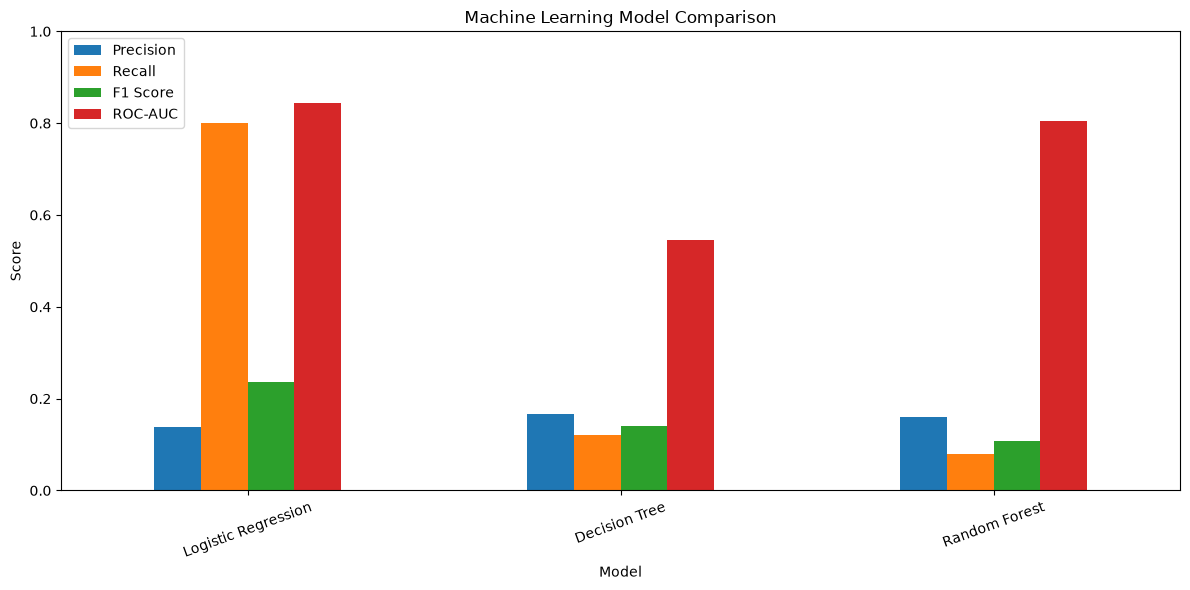

In [72]:
# Compare important evaluation metrics
metrics_to_plot = [
    "Precision",
    "Recall",
    "F1 Score",
    "ROC-AUC"
]

results_df.set_index("Model")[metrics_to_plot].plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title("Machine Learning Model Comparison")
plt.xlabel("Model")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

#### 11.3 Select the best model

In [73]:
# Select the model with the highest F1-score
best_model_name = results_df.iloc[0]["Model"]
best_model = trained_models[best_model_name]

print("Selected model:", best_model_name)
print("F1-score:", round(results_df.iloc[0]["F1 Score"], 4))
print("Recall:", round(results_df.iloc[0]["Recall"], 4))
print("Precision:", round(results_df.iloc[0]["Precision"], 4))
print("ROC-AUC:", round(results_df.iloc[0]["ROC-AUC"], 4))

Selected model: Logistic Regression
F1-score: 0.2353
Recall: 0.8
Precision: 0.1379
ROC-AUC: 0.8436


### Step 12: Final evaluation of the selected model

#### 12.1 Classification report

In [74]:
# Generate predictions from the selected model
y_pred_best = best_model.predict(X_test)

# Display precision, recall and F1-score for each class
print(
    classification_report(
        y_test,
        y_pred_best,
        target_names=["No Stroke", "Stroke"],
        zero_division=0
    )
)

              precision    recall  f1-score   support

   No Stroke       0.99      0.74      0.85       972
      Stroke       0.14      0.80      0.24        50

    accuracy                           0.75      1022
   macro avg       0.56      0.77      0.54      1022
weighted avg       0.94      0.75      0.82      1022



#### 12.2 Confusion matrix

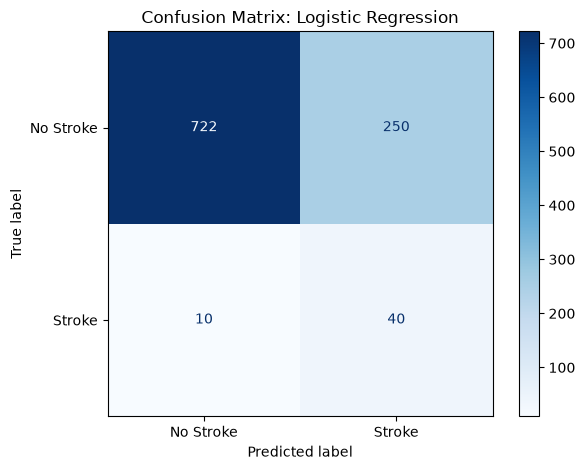

In [75]:
# Display the confusion matrix
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_best,
    display_labels=["No Stroke", "Stroke"],
    cmap="Blues",
    values_format="d"
)

plt.title(f"Confusion Matrix: {best_model_name}")
plt.tight_layout()
plt.show()

#### 12.3 Display the final scores

In [76]:
# Calculate final evaluation metrics
y_prob_best = best_model.predict_proba(X_test)[:, 1]

print("Final Model:", best_model_name)
print("Accuracy:", round(accuracy_score(y_test, y_pred_best), 4))
print(
    "Precision:",
    round(precision_score(y_test, y_pred_best, zero_division=0), 4)
)
print(
    "Recall:",
    round(recall_score(y_test, y_pred_best, zero_division=0), 4)
)
print(
    "F1-score:",
    round(f1_score(y_test, y_pred_best, zero_division=0), 4)
)
print("ROC-AUC:", round(roc_auc_score(y_test, y_prob_best), 4))

Final Model: Logistic Regression
Accuracy: 0.7456
Precision: 0.1379
Recall: 0.8
F1-score: 0.2353
ROC-AUC: 0.8436


### Step 13: Save the trained model

In [77]:
# Import Joblib when saving the model
import joblib

# Save the selected model pipeline
joblib.dump(best_model, "stroke_prediction_model.pkl")

print("Model saved successfully!")

Model saved successfully!


#### 13.1 Load and verify the saved model

In [78]:
import numpy as np
import pandas as pd

In [79]:
# Load the saved pipeline
loaded_model = joblib.load("stroke_prediction_model.pkl")

# Select one test record
sample_patient = X_test.iloc[[0]]

# Compare predictions before and after loading
original_prediction = best_model.predict(sample_patient)
loaded_prediction = loaded_model.predict(sample_patient)

print("Original prediction:", original_prediction[0])
print("Loaded model prediction:", loaded_prediction[0])

assert np.array_equal(original_prediction, loaded_prediction)

print("Model verification successful!")

Original prediction: 0
Loaded model prediction: 0
Model verification successful!


### Step 14: Test a sample prediction in Jupyter Notebook

In [80]:
# Select a sample patient from the test set
sample_patient = X_test.iloc[[0]]

# Predict the class
prediction = loaded_model.predict(sample_patient)[0]

# Calculate the model score for the stroke class
stroke_score = loaded_model.predict_proba(sample_patient)[0, 1]

print("Patient information:")
display(sample_patient)

print("\nPredicted class:")

if prediction == 1:
    print("Stroke class predicted")
else:
    print("No-stroke class predicted")

print(f"Model score for stroke class: {stroke_score:.2%}")
print("Actual class:", int(y_test.iloc[0]))

Patient information:


,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status
3725,Male,63.0,0,0,Yes,Private,Rural,78.23,34.8,never smoked



Predicted class:
No-stroke class predicted
Model score for stroke class: 46.09%
Actual class: 0


In [81]:
%pip install gradio

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: C:\Users\VENU\AppData\Local\Python\pythoncore-3.14-64\python.exe -m pip install --upgrade pip


In [82]:
import gradio as gr
import pandas as pd
import joblib

In [83]:
model = joblib.load("stroke_prediction_model.pkl")

print("Stroke prediction model loaded successfully!")

Stroke prediction model loaded successfully!


In [84]:
def predict_stroke(
    gender,
    age,
    hypertension,
    heart_disease,
    ever_married,
    work_type,
    residence_type,
    avg_glucose_level,
    bmi,
    smoking_status
):
    # Validate inputs
    if age is None or not 0 <= age <= 120:
        raise gr.Error("Please enter an age between 0 and 120.")

    if avg_glucose_level is None or avg_glucose_level < 0:
        raise gr.Error("Please enter a non-negative glucose level.")

    if bmi is None or bmi <= 0:
        raise gr.Error("Please enter a positive BMI.")

    # Create a DataFrame with the model's expected columns
    patient = pd.DataFrame([{
        "gender": gender,
        "age": age,
        "hypertension": hypertension,
        "heart_disease": heart_disease,
        "ever_married": ever_married,
        "work_type": work_type,
        "Residence_type": residence_type,
        "avg_glucose_level": avg_glucose_level,
        "bmi": bmi,
        "smoking_status": smoking_status
    }])

    # Predict the class and its estimated score
    prediction = model.predict(patient)[0]
    probability = model.predict_proba(patient)[0, 1]

    if prediction == 1:
        result = "Stroke class predicted"
    else:
        result = "No-stroke class predicted"

    score = (
        f"Model score for stroke class: {probability:.2%}\n"
        "This is not a validated clinical risk estimate."
    )

    return result, score

In [85]:
with gr.Blocks(title="Stroke Prediction") as demo:

    gr.Markdown("""
    # Stroke Prediction Using Machine Learning

    Enter the patient information and click **Predict**.

    **Disclaimer:** This is an educational ML project, not a
    medical diagnostic tool.
    """)

    with gr.Row():
        gender = gr.Dropdown(
            ["Female", "Male", "Other"],
            value="Female",
            label="Gender"
        )

        age = gr.Number(
            value=45,
            minimum=0,
            maximum=120,
            label="Age"
        )

    with gr.Row():
        hypertension = gr.Dropdown(
            [0, 1],
            value=0,
            label="Hypertension (0 = No, 1 = Yes)"
        )

        heart_disease = gr.Dropdown(
            [0, 1],
            value=0,
            label="Heart Disease (0 = No, 1 = Yes)"
        )

    with gr.Row():
        ever_married = gr.Dropdown(
            ["No", "Yes"],
            value="Yes",
            label="Ever Married"
        )

        work_type = gr.Dropdown(
            [
                "Private",
                "Self-employed",
                "Govt_job",
                "children",
                "Never_worked"
            ],
            value="Private",
            label="Work Type"
        )

    with gr.Row():
        residence_type = gr.Dropdown(
            ["Urban", "Rural"],
            value="Urban",
            label="Residence Type"
        )

        smoking_status = gr.Dropdown(
            [
                "formerly smoked",
                "never smoked",
                "smokes",
                "Unknown"
            ],
            value="never smoked",
            label="Smoking Status"
        )

    with gr.Row():
        avg_glucose_level = gr.Number(
            value=100.0,
            minimum=0,
            label="Average Glucose Level"
        )

        bmi = gr.Number(
            value=25.0,
            minimum=0,
            label="BMI"
        )

    predict_button = gr.Button(
        "Predict",
        variant="primary"
    )

    result_output = gr.Textbox(
        label="Prediction Result"
    )

    score_output = gr.Textbox(
        label="Model Score"
    )

    predict_button.click(
        fn=predict_stroke,
        inputs=[
            gender,
            age,
            hypertension,
            heart_disease,
            ever_married,
            work_type,
            residence_type,
            avg_glucose_level,
            bmi,
            smoking_status
        ],
        outputs=[
            result_output,
            score_output
        ]
    )

In [86]:
demo.launch()

* Running on local URL:  http://127.0.0.1:7861
* To create a public link, set `share=True` in `launch()`.


In [87]:
demo.launch(share = True, inline = False)

Rerunning server... use `close()` to stop if you need to change `launch()` parameters.
----

Could not create share link. Please check your internet connection or our status page: https://status.gradio.app.
